# Regresión lineal con gradiente descendente

Implementación desde cero de la regresión lineal simple: función de costo, solución exacta por ecuación normal y gradiente descendente, con la superficie y las curvas de nivel del costo para ver el camino que sigue el algoritmo. Al final se contrasta con `SGDRegressor` de scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import SGDRegressor

# Datos sintéticos: 100 puntos, una variable, ruido gaussiano; coef es la pendiente real
X, y, coef = make_regression(n_samples=100, n_features=1, noise=10, coef=True, random_state=42)
X_bias = np.c_[np.ones(len(y)), X]   # columna de unos para el intercepto θ₀
print(f'Pendiente real: {coef:.2f} (intercepto real: 0)')

Pendiente real: 41.74 (intercepto real: 0)


## 1. Función de costo y solución exacta

El costo es el error cuadrático medio (con el factor ½ habitual, que simplifica el gradiente):

$$J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(\theta_0 + \theta_1 x_i - y_i\right)^2$$

La ecuación normal $\theta = (X^\top X)^{-1}X^\top y$ da el mínimo exacto y sirve de referencia.

In [2]:
def costo(X_bias, y, theta):
    error = X_bias @ theta - y
    return (error @ error) / (2 * len(y))

def ecuacion_normal(X_bias, y):
    return np.linalg.solve(X_bias.T @ X_bias, X_bias.T @ y)

theta_exacto = ecuacion_normal(X_bias, y)
print(f'Ecuación normal: θ₀ = {theta_exacto[0]:.3f}, θ₁ = {theta_exacto[1]:.3f}, costo = {costo(X_bias, y, theta_exacto):.2f}')

Ecuación normal: θ₀ = 1.165, θ₁ = 44.437, costo = 39.03


## 2. Gradiente descendente

En cada iteración, $\theta \leftarrow \theta - \alpha \nabla J(\theta)$, con $\nabla J(\theta) = \frac{1}{m}X^\top(X\theta - y)$. Se parte de θ = (0, 0) y se guarda el historial para graficar el recorrido.

In [3]:
def gradiente_descendente(X_bias, y, alpha=0.1, iteraciones=200, theta_inicial=(0.0, 0.0)):
    theta = np.array(theta_inicial, dtype=float)
    historial = [theta.copy()]
    costos = [costo(X_bias, y, theta)]
    for _ in range(iteraciones):
        theta -= alpha * X_bias.T @ (X_bias @ theta - y) / len(y)
        historial.append(theta.copy())
        costos.append(costo(X_bias, y, theta))
    return np.array(historial), np.array(costos)

historial, costos = gradiente_descendente(X_bias, y)
theta_gd = historial[-1]
print(f'Gradiente descendente: θ₀ = {theta_gd[0]:.3f}, θ₁ = {theta_gd[1]:.3f}, costo = {costos[-1]:.2f}')

for alpha in (0.01, 0.1, 0.5):
    _, c = gradiente_descendente(X_bias, y, alpha=alpha)
    llega = np.argmax(c <= costo(X_bias, y, theta_exacto) * 1.01)
    print(f'α = {alpha}: costo final {c[-1]:.2f}; llega a 1 % del mínimo en la iteración {llega if c[-1] <= costo(X_bias, y, theta_exacto) * 1.01 else "—"}')

Gradiente descendente: θ₀ = 1.165, θ₁ = 44.437, costo = 39.03
α = 0.01: costo final 69.81; llega a 1 % del mínimo en la iteración —
α = 0.1: costo final 39.03; llega a 1 % del mínimo en la iteración 46
α = 0.5: costo final 39.03; llega a 1 % del mínimo en la iteración 8


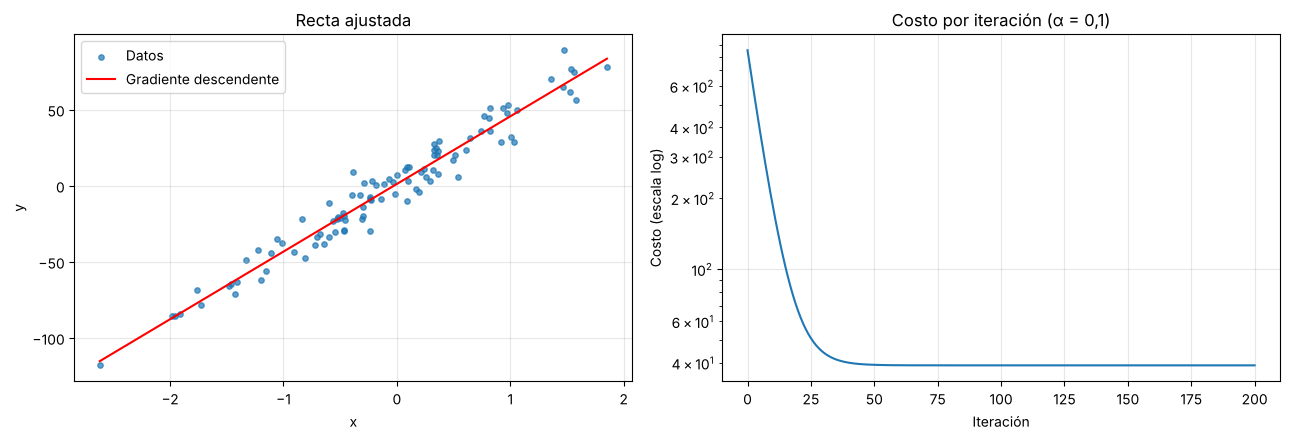

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].scatter(X, y, s=15, alpha=0.7, label='Datos')
xs = np.linspace(X.min(), X.max(), 100)
ejes[0].plot(xs, theta_gd[0] + theta_gd[1] * xs, color='red', label='Gradiente descendente')
ejes[0].set_xlabel('x')
ejes[0].set_ylabel('y')
ejes[0].set_title('Recta ajustada')
ejes[0].legend()

ejes[1].plot(costos)
ejes[1].set_yscale('log')
ejes[1].set_xlabel('Iteración')
ejes[1].set_ylabel('Costo (escala log)')
ejes[1].set_title('Costo por iteración (α = 0,1)')
for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Superficie del costo

La malla se centra en la solución exacta para que se vea el mínimo. Las curvas de nivel muestran el recorrido del gradiente descendente desde (0, 0).

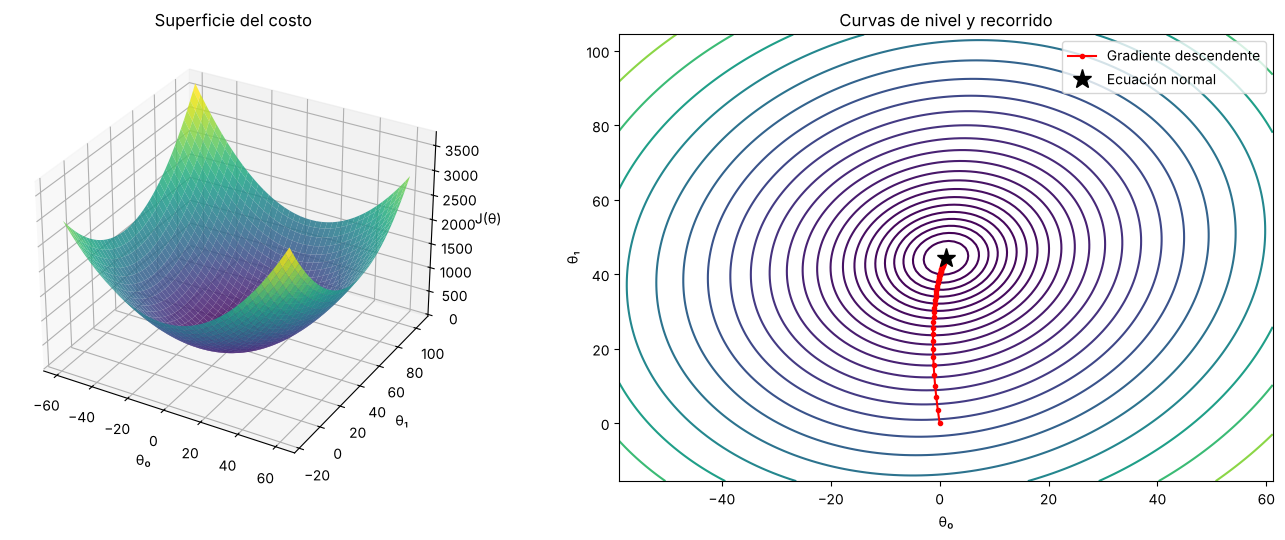

In [5]:
t0 = np.linspace(theta_exacto[0] - 60, theta_exacto[0] + 60, 120)
t1 = np.linspace(theta_exacto[1] - 60, theta_exacto[1] + 60, 120)
T0, T1 = np.meshgrid(t0, t1)
J = np.array([[costo(X_bias, y, np.array([a, b])) for a in t0] for b in t1])

fig = plt.figure(figsize=(14, 5.5))
ax3d = fig.add_subplot(1, 2, 1, projection='3d')
ax3d.plot_surface(T0, T1, J, cmap='viridis', alpha=0.85)
ax3d.set_xlabel('θ₀')
ax3d.set_ylabel('θ₁')
ax3d.set_zlabel('J(θ)')
ax3d.set_title('Superficie del costo')

ax = fig.add_subplot(1, 2, 2)
ax.contour(T0, T1, J, levels=np.logspace(np.log10(J.min()), np.log10(J.max()), 25), cmap='viridis')
ax.plot(historial[:, 0], historial[:, 1], 'o-', color='red', markersize=3, label='Gradiente descendente')
ax.plot(*theta_exacto, 'k*', markersize=14, label='Ecuación normal')
ax.set_xlabel('θ₀')
ax.set_ylabel('θ₁')
ax.set_title('Curvas de nivel y recorrido')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Comparación con scikit-learn

In [6]:
sgd = SGDRegressor(max_iter=1000, tol=1e-3, random_state=42).fit(X, y)

tabla = pd.DataFrame({
    'θ₀ (intercepto)': [0.0, theta_exacto[0], theta_gd[0], sgd.intercept_[0]],
    'θ₁ (pendiente)': [float(coef), theta_exacto[1], theta_gd[1], sgd.coef_[0]],
}, index=['Valor real', 'Ecuación normal', 'Gradiente descendente', 'SGDRegressor'])
tabla['costo'] = [np.nan] + [costo(X_bias, y, np.array(r)) for r in tabla.iloc[1:, :2].values]
display(tabla.round(3))

,θ₀ (intercepto),θ₁ (pendiente),costo
Valor real,0.000,41.741,NaN
Ecuación normal,1.165,44.437,39.027
Gradiente descendente,1.165,44.437,39.027
SGDRegressor,1.148,44.424,39.027


**Análisis**

- El gradiente descendente con α = 0,1 llega al mismo resultado que la ecuación normal (θ₀ = 1,165, θ₁ = 44,437) y a 1 % del costo mínimo en 46 iteraciones. Con α = 0,5 llega en 8; con α = 0,01, 200 iteraciones no le alcanzan.
- En las curvas de nivel el recorrido avanza casi en línea recta hacia el mínimo: con una sola variable y datos centrados, el costo es un tazón casi circular y el gradiente apunta directo a él.
- La pendiente estimada (44,4) se aleja de la real (41,7) por el ruido de los 100 puntos, no por el método: la ecuación normal, el gradiente descendente propio y `SGDRegressor` coinciden en el mismo costo.